# FIRELINE — Prioritas area & dashboard yang dapat dijelaskan

Notebook 06 mengubah hasil audit menjadi dashboard fitur **Mapping / Peta Prioritas Titik Api**. Mulai dari pertanyaan pengguna: **area mana yang perlu lebih diperhatikan pada tanggal yang saya pilih, dan mengapa?**

Pipeline lengkap berjalan di sel pertama sesudah konfigurasi. Sel-sel berikut memeriksa hasil dan menjelaskan keputusan. Skor ini adalah heuristik untuk prototipe historis; label kejadian terverifikasi belum tersedia.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "fireline").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from fireline.pipeline import settings, audit, build
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
config = settings(ROOT / "config.local.json")

In [2]:
summary, grids = build(ROOT / "config.local.json")
display(Markdown(f"**{summary['kalimantan_observations']:,} observasi → {summary['grid_day_rows']:,} grid-hari; {summary['unique_grids']:,} grid unik.**"))
display(pd.DataFrame(summary["stage_counts"]))

E:\DSA-FINAL\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: OGRGeoJSONReadRawPoint(): too many members in array '[ 110.20399999999999, -3.0646, 0.0, null ]': 4. At most 3 are handled. Ignoring extra members. Further messages of this type will be suppressed.
  return ogr_read(


**60,708 observasi → 26,773 grid-hari; 2,846 grid unik.**

,stage,retained,removed
0,Mentah,61583,0
1,Duplikat persis dihapus,61583,0
2,Koordinat dan waktu valid,61583,0
3,Type 0 (dugaan api vegetasi),61583,0
4,Di dalam poligon BIG Kalimantan,60708,875


## 1. Mengelompokkan observasi menjadi area

Grid 0,1° adalah kotak bantu sekitar 11 km per sisi di sekitar khatulistiwa. Satu kunci `grid_id + date` berarti satu kotak pada satu tanggal UTC. Ini bukan pemisahan kejadian kebakaran yang telah divalidasi.

Marker ditempatkan pada **observasi dengan FRP tertinggi dalam grid-hari**, bukan pusat grid. Jarak sekolah dihitung dari marker representatif itu. Jadi angka jaraknya tidak bisa dibandingkan langsung dengan median seluruh observasi atau median pusat grid pada baseline lama.

Grid yang melewati batas provinsi diberi catatan. Untuk filter, label provinsi mengikuti observasi representatif; hitungan provinsi di audit tetap dihitung dari setiap observasi asli.

In [3]:
cols=["grid_id","date","province_name","region_name","detection_count","latitude","longitude","active_days_7d","detections_7d","frp_median_mw"]
display(grids[cols].head(12))
assert not grids.duplicated(["grid_id","date"]).any()
assert grids.detection_count.sum() == summary["kalimantan_observations"]
assert grids.active_days_7d.between(1,7).all()

,grid_id,date,province_name,region_name,detection_count,latitude,longitude,active_days_7d,detections_7d,frp_median_mw
0,6:1101,2024-08-01,Kalimantan Barat,Landak,7,0.64370,110.13029,1,7,23.080
1,3:1104,2024-08-01,Kalimantan Barat,Sanggau,5,0.30698,110.43472,1,5,14.400
2,7:1097,2024-08-01,Kalimantan Barat,Landak,6,0.76370,109.75989,1,6,10.665
3,-3:1119,2024-08-01,Kalimantan Barat,Melawi,4,-0.24846,111.92082,1,4,14.065
4,4:1105,2024-08-01,Kalimantan Barat,Sanggau,3,0.47567,110.57555,1,3,21.610
5,1:1109,2024-08-01,Kalimantan Barat,Sekadau,3,0.16237,110.92505,1,3,15.350
6,7:1104,2024-08-01,Kalimantan Barat,Sanggau,4,0.79866,110.41123,1,4,8.845
7,3:1105,2024-08-01,Kalimantan Barat,Sanggau,3,0.35518,110.52242,1,3,12.170
8,-1:1106,2024-08-01,Kalimantan Barat,Sanggau,2,-0.06769,110.66745,1,2,49.680
9,-21:1109,2024-08-01,Kalimantan Barat,Ketapang,2,-2.06552,110.91424,1,2,46.600


## 2. Tiga pertanyaan yang membentuk skor

1. **Aktivitas:** seberapa banyak observasi di area itu pada hari terpilih? Diubah menjadi persentil di antara semua area aktif Kalimantan pada hari yang sama.
2. **Persistensi:** berapa tanggal berbeda area ini muncul dalam tujuh hari termasuk hari terpilih? Dibagi 7; pengamatan berulang tidak otomatis membuktikan api menyala terus.
3. **FRP:** seberapa tinggi nilai tengah radiasi panas area itu dibanding area lain pada hari yang sama?

`skor = 40 × aktivitas + 35 × persistensi + 25 × FRP`.

Perubahan dari baseline v2: persistensi memakai **hari aktif/7**, bukan persentil total deteksi tujuh hari. Ini membedakan frekuensi hari dari volume observasi, walaupun keduanya masih dapat berkorelasi. Mid-rank mencegah satu area aktif otomatis mendapat persentil 100. Skor nol/tidak terisi bukan pernyataan wilayah aman.

Batas awal: P1 ≥80, P2 60–<80, P3 <60. Batas ini asumsi desain, bukan batas bahaya yang tervalidasi. Skor relatif harian tidak dipakai untuk membuktikan tren risiko antartanggal. Filter provinsi/P1 menyaring tampilan tanpa menghitung ulang pembanding.

,grid_id,region_name,priority_level,priority_score,activity_points,persistence_points,intensity_points
2447,-3:1125,Sintang,P1,80.1040,36.514851,20.0,23.589109
2448,-7:1102,Ketapang,P2,79.2327,35.841584,20.0,23.391089
2449,-4:1107,Sekadau,P2,78.9851,39.801980,20.0,19.183168
2450,6:1096,Landak,P2,78.9356,35.841584,20.0,23.094059
2451,-1:1110,Sekadau,P2,76.6485,38.851485,20.0,17.797030
2452,-6:1105,Ketapang,P2,76.1535,37.465347,15.0,23.688119
2453,-3:1107,Sekadau,P2,73.8663,38.495050,15.0,20.371287
2454,-5:1104,Ketapang,P2,73.8168,39.881188,15.0,18.935644
2455,2:1122,Kapuas Hulu,P2,73.8168,36.514851,15.0,22.301980
2456,-9:1103,Ketapang,P2,73.1931,35.841584,15.0,22.351485


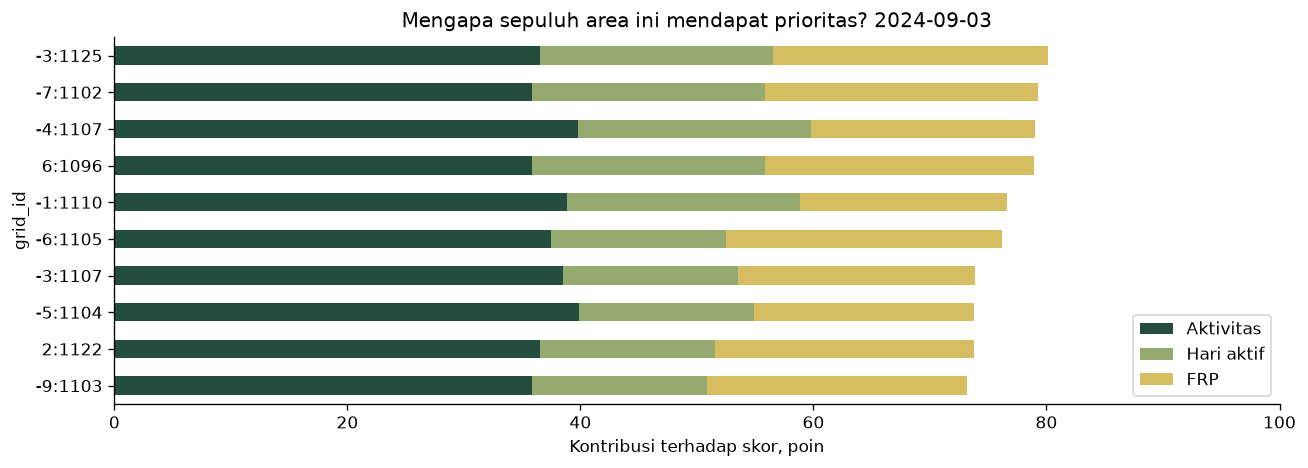

In [4]:
demo = grids.loc[grids.date.eq(summary["demo_date"])].sort_values(["priority_score","grid_id"], ascending=[False,True])
display(demo[["grid_id","region_name","priority_level","priority_score","activity_points","persistence_points","intensity_points"]].head(10))
assert np.allclose(grids.priority_score, grids.activity_points + grids.persistence_points + grids.intensity_points, atol=0.0001)
fig, ax = plt.subplots(figsize=(11,4))
top = demo.head(10).set_index("grid_id")[["activity_points","persistence_points","intensity_points"]]
top.plot.barh(stacked=True, ax=ax, color=["#244d40","#94aa6f","#d6bd62"])
ax.invert_yaxis(); ax.set_xlim(0,100); ax.set_xlabel("Kontribusi terhadap skor, poin")
ax.set_title("Mengapa sepuluh area ini mendapat prioritas? " + summary["demo_date"])
ax.legend(["Aktivitas","Hari aktif","FRP"], loc="lower right")
plt.tight_layout(); plt.show()

## 3. Apakah fitur saling berhubungan?

Korelasi Spearman mengukur apakah nilai yang lebih tinggi pada satu fitur cenderung beriringan dengan fitur lain. Mendekati +1 berarti urutannya cenderung sama, mendekati -1 berarti berlawanan, dan mendekati 0 berarti tidak ada hubungan monoton yang kuat dalam sampel ini.

Tabel ini bersifat deskriptif atas grid-hari, dengan pengamatan berulang dari area yang sama. Korelasi tidak membuktikan penyebab atau validitas skor. Kami tidak menghitung korelasi cuaca yang tanggalnya digeser.

,detection_count,active_days_7d,frp_median_mw
detection_count,1.000,0.248,0.288
active_days_7d,0.248,1.000,0.063
frp_median_mw,0.288,0.063,1.000


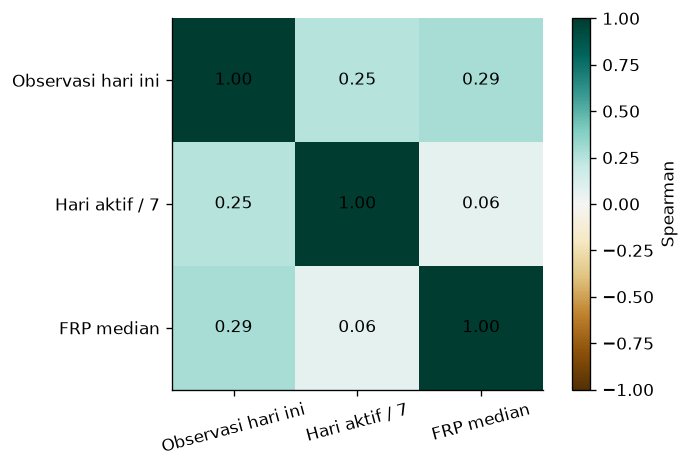

In [5]:
corr_cols=["detection_count","active_days_7d","frp_median_mw"]
correlation=grids[corr_cols].corr(method="spearman")
display(correlation.round(3))
fig, ax=plt.subplots(figsize=(6,4))
im=ax.imshow(correlation,vmin=-1,vmax=1,cmap="BrBG")
ax.set_xticks(range(3),["Observasi hari ini","Hari aktif / 7","FRP median"],rotation=15)
ax.set_yticks(range(3),["Observasi hari ini","Hari aktif / 7","FRP median"])
for i in range(3):
    for j in range(3): ax.text(j,i,f"{correlation.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im,ax=ax,label="Spearman");plt.tight_layout();plt.show()

## 4. Uji bobot: apakah Top 10 mudah berubah?

Kami membandingkan 40/35/25 dengan bobot sama, penekanan aktivitas, penekanan persistensi, dan penghapusan satu fitur. Jaccard adalah anggota yang sama dibagi seluruh anggota unik dari dua daftar. 1 berarti daftar sama; 0 berarti tidak ada anggota bersama.

Hanya hari dengan lebih dari 10 area yang masuk ringkasan: jika areanya cuma 5, dua daftar Top 10 pasti memuat kelimanya dan terlihat stabil secara semu. Uji ini menilai kestabilan, belum mengukur akurasi atau manfaat lapangan.

,variant,days_with_more_than_10_areas,mean_top10_jaccard,min_top10_jaccard
0,equal_three,362,0.8668,0.4286
1,activity_heavy,362,0.8809,0.4286
2,persistence_heavy,362,0.7931,0.2500
3,without_activity,362,0.5739,0.0000
4,without_persistence,362,0.7429,0.1111
5,without_intensity,362,0.6005,0.1765


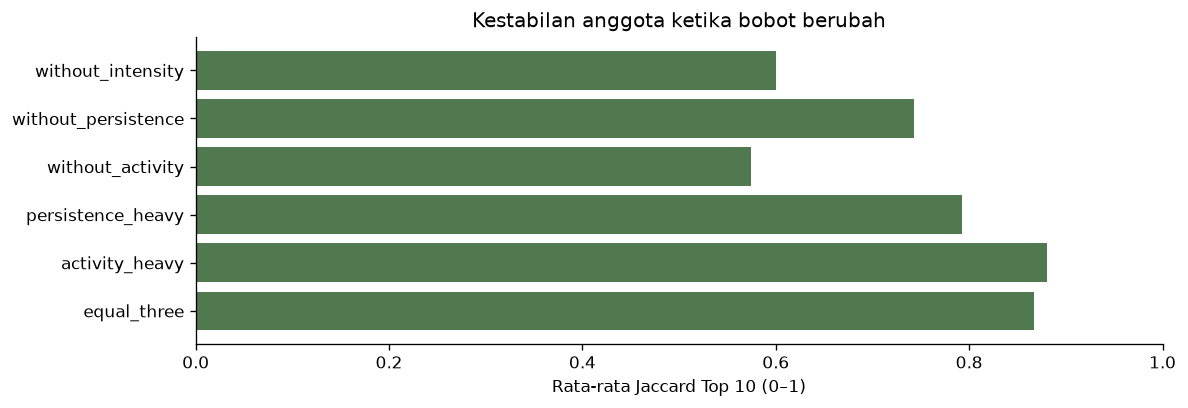

,grid_days
priority_level,
P3,22879
P2,3663
P1,231


In [6]:
sensitivity_table = pd.DataFrame(summary["sensitivity"])
display(sensitivity_table.drop(columns="weights"))
fig, ax=plt.subplots(figsize=(10,3.5))
ax.barh(sensitivity_table.variant, sensitivity_table.mean_top10_jaccard, color="#517950")
ax.set_xlim(0,1);ax.set_xlabel("Rata-rata Jaccard Top 10 (0–1)")
ax.set_title("Kestabilan anggota ketika bobot berubah")
plt.tight_layout();plt.show()
display(grids.priority_level.value_counts().to_frame("grid_days"))

## 5. Sekolah dan batas kab/kota sebagai konteks

School distance tidak masuk rumus. Kedekatan geografis belum membuktikan paparan asap, anak-anak terdampak, atau sekolah beroperasi. Boundary kab/kota dipulihkan dari HTML Kaka; seluruh skor, confidence agregat, dan ranking lama dibuang. Sumber/tahun boundary kab/kota perlu dikonfirmasi sebelum publikasi final.

In [7]:
display(grids[["grid_id","date","nearest_school_name","nearest_school_km","quality_note"]].head(8))
print("Sekolah yang masuk poligon:", summary["schools_in_boundary"])
print("Median jarak observasi representatif per grid-hari:", summary["median_representative_school_km"],"km")
print("Grid-hari tanpa label kab/kota:", summary["unmapped_representative_grid_days"])
print(summary["region_note"])

,grid_id,date,nearest_school_name,nearest_school_km,quality_note
0,6:1101,2024-08-01,SD NEGERI 11 SEMUNTI,1.448973,Jendela awal kurang dari 7 hari
1,3:1104,2024-08-01,SD NEGERI 33 MODAH,3.319111,Jendela awal kurang dari 7 hari
2,7:1097,2024-08-01,SD NEGERI 13 MORO BEHE II,1.695686,Jendela awal kurang dari 7 hari
3,-3:1119,2024-08-01,SMA NEGERI 1 PINOH UTARA,3.280353,Jendela awal kurang dari 7 hari
4,4:1105,2024-08-01,SD NEGERI 10 BANTAI,3.239907,Jendela awal kurang dari 7 hari
5,1:1109,2024-08-01,SMP NEGERI 2 SEKADAU HILIR,1.208809,Jendela awal kurang dari 7 hari
6,7:1104,2024-08-01,SD NEGERI 28 ENTABAI,0.325203,Jendela awal kurang dari 7 hari
7,3:1105,2024-08-01,SD NEGERI 23 UPE,1.705125,Jendela awal kurang dari 7 hari


Sekolah yang masuk poligon: 17278
Median jarak observasi representatif per grid-hari: 2.843 km
Grid-hari tanpa label kab/kota: 56
Kab/kota dari HTML Kaka; sumber dan tahun boundary belum tercantum. Hanya konteks visual.


## 6. Dashboard dan keterlacakan hasil

Dashboard HTML dan Streamlit memakai payload yang sama. Top 10 pada daftar, nomor marker, dan detail berasal dari pemilahan data yang sama. Tanggal terpilih adalah filter satu hari; konteks persistensi/tren memakai tujuh hari terakhir.

Snapshot historis yang dibuka sebagai demo dipilih pada hari observasi terbanyak. Waktu pembangunan file dan waktu observasi ditampilkan terpisah. Pengiriman notifikasi, Community, dan verifikasi laporan tetap mengikuti keputusan produk terpisah dan tidak dijalankan di sini.

In [8]:
artifact = ROOT / "review_outputs" / "FIRELINE_Priority_Map.html"
assert artifact.exists()
display(Markdown("[Buka dashboard HTML](../review_outputs/FIRELINE_Priority_Map.html)"))
display(pd.DataFrame(summary["sources"]).T[["file","sha256"]])
print("Ukuran dashboard:",round(artifact.stat().st_size/1024/1024,2),"MB")
print("Selesai. Dashboard dapat dibuka langsung atau melalui Streamlit.")

[Buka dashboard HTML](../review_outputs/FIRELINE_Priority_Map.html)

,file,sha256
firms_csv,fireline_hotspot_kalimantan_viirs_noaa20_2024_...,c1661c7b6652b111e5652e172e7d8ad21a3f7b45eb018a...
provinces_geojson,kalimantan_provinces.geojson,8ca724dba471b515e9e0c0a5e51aa125169bfaed3023ee...
schools_csv,complete_data.csv,9fecf9e24dcebe082aab0ac3f5c5cd815d6f8336c26f7d...
kaka_html,composite_score_explainable_map_v2.html,2cbfc7458066224ba1e44982a31338dbc2c02b543ef54d...


Ukuran dashboard: 6.54 MB
Selesai. Dashboard dapat dibuka langsung atau melalui Streamlit.


## Pertanyaan yang tetap dibawa saat review

- PMA/UX mengonfirmasi apakah istilah area-grid diterima sebagai representasi titik prioritas; grid 0,1° belum kalibrasi resolusi operasional.
- Bobot dan ambang kategori perlu masukan domain serta uji dengan label lapangan.
- Estimasi dampak belum tersedia. Cuaca/populasi tidak boleh diisi dengan data yang tidak sesuai ruang/waktu.
- Data utama tetap sumber resmi observasi; sumber tambahan menjadi konteks yang keterbatasannya dicatat.

Sumber: [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/active_fire/), [BIG](https://geoservices.big.go.id/gis/rest/services/STIG/Batas_Provinsi/MapServer), [referensi sekolah](https://www.kaggle.com/datasets/marchotridyo/indonesia-school-dataset-with-province-data).